# 01 — Análise Exploratória dos Dados
## SINASC 2014–2024

## 1. Objetivo

O **SINASC** (Sistema de Informações sobre Nascidos Vivos) é o sistema do Ministério da Saúde que registra os nascimentos vivos do Brasil a partir da **Declaração de Nascido Vivo (DNV)**. Este projeto usa os microdados públicos de **2014 a 2024**: onze anos e cerca de 30,5 milhões de registros.

**Pergunta geral do projeto.** Entre gestantes com características semelhantes, iniciar o pré-natal até o 3º mês de gestação está associado a um risco menor de **baixo peso ao nascer** (peso inferior a 2.500 g) do que iniciar mais tarde? A pergunta é examinada separadamente em cada ano.

**O que este notebook explora:**

- volume e estrutura da base;
- qualidade de preenchimento dos campos usados;
- o desfecho (peso ao nascer), a exposição (mês de início do pré-natal) e as características maternas;
- a evolução desses elementos entre 2014 e 2024.

Todas as comparações deste notebook são **descritivas**. A definição formal da população e do desenho analítico fica para o notebook 02.

### Preparação do ambiente

As estatísticas anuais vêm de tabelas já consolidadas a partir dos 30,5 milhões de registros (`outputs/temporal/tabelas/`). Quando uma figura precisa de microdados (histogramas e Tabela 1), a consulta é feita diretamente nos arquivos Parquet com DuckDB, só para 2014 e 2024.

In [1]:
from pathlib import Path
import json
import sys

import duckdb
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display

# ------------------------------------------------------------
# Raiz do projeto: procurada nos diretórios pais, sem caminho fixo
# ------------------------------------------------------------
cwd = Path.cwd().resolve()
raiz = next(
    (p for p in [cwd, *cwd.parents]
     if (p / "src" / "temporal.py").exists()
     and (p / "docs" / "entrega" / "METADADOS_BASE.md").exists()),
    None,
)
if raiz is None:
    raise FileNotFoundError(f"Raiz do projeto não encontrada a partir de {cwd}")
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

venv_projeto = (raiz / ".venv").resolve()
if Path(sys.prefix).resolve() != venv_projeto:
    print(f"Atenção: o kernel não está usando a .venv do projeto ({venv_projeto}).")

from src.temporal import caminhos_ano
from src.visualizacao import CORES_IPT, aplicar_tema_base, configurar_plotly

configurar_plotly()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

ANOS = list(range(2014, 2025))
TABELAS = raiz / "outputs" / "temporal" / "tabelas"
con = duckdb.connect()


def num(valor, casas=0):
    """Formata número no padrão brasileiro: 1.234.567,89."""
    texto = f"{valor:,.{casas}f}"
    return texto.replace(",", "§").replace(".", ",").replace("§", ".")


def mostrar(fig, titulo, altura=460, largura=950, margem_esquerda=None):
    """Aplica a identidade visual IPT e exibe a figura."""
    aplicar_tema_base(fig, titulo)
    fig.update_layout(width=largura, height=altura, separators=",.")
    if margem_esquerda is not None:
        fig.update_layout(margin_l=margem_esquerda)
    fig.show()


def formatar(tabela, casas=2):
    """Converte uma tabela numérica para texto no padrão brasileiro."""
    return tabela.map(lambda v: "—" if pd.isna(v) else num(v, casas))


def parquet(ano):
    """Caminho do Parquet anual, já em formato aceito pelo DuckDB."""
    return caminhos_ano(raiz, ano).parquet.as_posix()


print("Raiz do projeto localizada:", raiz.name)

Raiz do projeto localizada: big-data-sinasc-causal-ml


In [2]:
descritiva = pd.read_csv(TABELAS / "descritiva_anual.csv").set_index("ano")
qualidade = pd.read_csv(TABELAS / "qualidade_anos.csv").set_index("ano")
estrutura = pd.read_csv(TABELAS / "auditoria_anos.csv").set_index("ano")
ausentes = pd.read_csv(TABELAS / "missing_anual.csv")
covariaveis = pd.read_csv(TABELAS / "covariaveis_anuais.csv", dtype={"categoria": str})
geografia = pd.read_csv(TABELAS / "geografia_anual.csv", dtype={"uf": str})

assert list(descritiva.index) == ANOS
assert descritiva.n_bruto.sum() == 30_468_409

# Rótulos em português para os códigos do SINASC
ROTULOS = {
    "ESCOLARIDADE_MAE": {"0": "Sem escolaridade", "1": "Fundamental I", "2": "Fundamental II",
                         "3": "Médio", "4": "Superior incompleto", "5": "Superior completo",
                         "IGNORADO": "Ignorado"},
    "RACA_COR_MAE": {"1": "Branca", "2": "Preta", "3": "Amarela", "4": "Parda",
                     "5": "Indígena", "IGNORADO": "Ignorado"},
    "SITUACAO_CONJUGAL": {"1": "Solteira", "2": "Casada", "3": "Viúva",
                          "4": "Separada/divorciada", "5": "União estável", "IGNORADO": "Ignorado"},
    "PARIDADE_CAT": {"0": "Nulípara", "1": "Multípara", "IGNORADO": "Ignorado"},
    "PERDAS_FETAIS_CAT": {"0": "Nenhuma", "1": "Uma", "2_OU_MAIS": "Duas ou mais",
                          "IGNORADO": "Ignorado"},
}
DIMENSOES = {
    "ESCOLARIDADE_MAE": "X2 Escolaridade",
    "RACA_COR_MAE": "X3 Raça/cor",
    "SITUACAO_CONJUGAL": "X4 Situação conjugal",
    "PARIDADE_CAT": "X5 Paridade",
    "PERDAS_FETAIS_CAT": "X6 Perdas fetais",
}
UF_SIGLA = {"11": "RO", "12": "AC", "13": "AM", "14": "RR", "15": "PA", "16": "AP", "17": "TO",
            "21": "MA", "22": "PI", "23": "CE", "24": "RN", "25": "PB", "26": "PE", "27": "AL",
            "28": "SE", "29": "BA", "31": "MG", "32": "ES", "33": "RJ", "35": "SP", "41": "PR",
            "42": "SC", "43": "RS", "50": "MS", "51": "MT", "52": "GO", "53": "DF"}
REGIAO = {"1": "Norte", "2": "Nordeste", "3": "Sudeste", "4": "Sul", "5": "Centro-Oeste"}

## 2. Fonte e granularidade

| Item | Descrição |
| --- | --- |
| **Fonte** | SINASC — Ministério da Saúde / DATASUS (Portal de Dados Abertos do SUS) |
| **Período** | 2014–2024, onze anos analisados separadamente |
| **Volume** | **30.468.409** registros brutos |
| **Granularidade** | 1 linha = 1 nascido vivo = 1 DNV |
| **Cobertura** | Brasil, 27 UFs, cerca de 5.580 municípios de residência por ano |
| **Colunas** | 61 de 2014 a 2022; 62 em 2023–2024 (campo novo `OPORT_DN`, não usado) |
| **Fluxo dos dados** | CSV anual oficial (ZIP) → Parquet, com todas as colunas preservadas como texto → consultas em DuckDB |

Não existe identificador da mãe. Nascimentos sucessivos da mesma mulher não podem ser ligados, e cada gêmeo gera a sua própria DNV.

Fichas completas: [METADADOS_BASE.md](../../docs/entrega/METADADOS_BASE.md) e [DICIONARIO_TECNICO.md](../../docs/entrega/DICIONARIO_TECNICO.md).

## 3. Volume por ano

In [3]:
volume = pd.DataFrame({
    "N de registros": descritiva.n_bruto,
    "Nº de colunas": estrutura.colunas_presentes,
}).rename_axis("Ano")

assert set(volume.loc[2014:2022, "Nº de colunas"]) == {61}
assert set(volume.loc[2023:2024, "Nº de colunas"]) == {62}

display(volume.assign(**{"N de registros": volume["N de registros"].map(num)}))
print("Total 2014–2024:", num(volume["N de registros"].sum()), "registros")

,N de registros,Nº de colunas
Ano,,
2014,2.979.259,61
2015,3.017.668,61
2016,2.857.800,61
2017,2.923.535,61
2018,2.944.932,61
2019,2.849.146,61
2020,2.730.145,61
2021,2.677.101,61
2022,2.561.922,61


Total 2014–2024: 30.468.409 registros


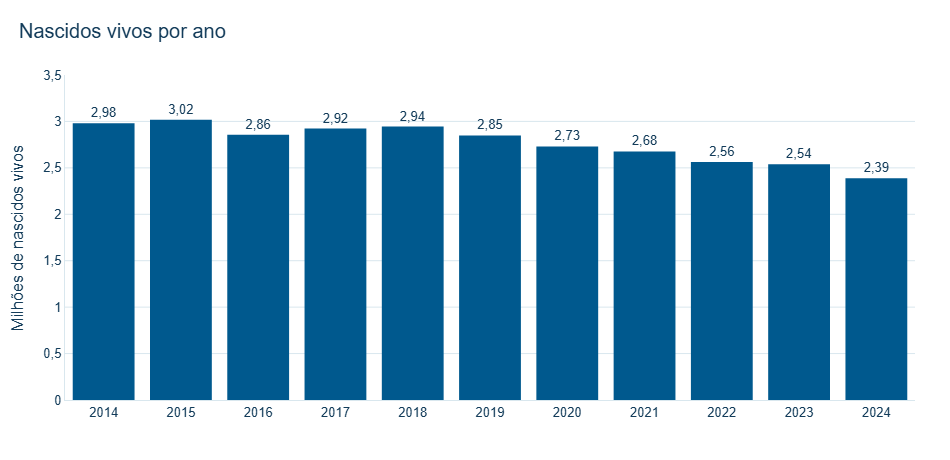

In [4]:
milhoes = volume["N de registros"] / 1e6
fig = go.Figure(go.Bar(
    x=volume.index, y=milhoes, marker_color=CORES_IPT["AZUL_PRINCIPAL"],
    text=[num(v, 2) for v in milhoes], textposition="outside",
))
fig.update_xaxes(dtick=1)
fig.update_yaxes(title="Milhões de nascidos vivos", range=[0, 3.5])
mostrar(fig, "Nascidos vivos por ano")

O número de nascidos vivos cai de forma quase contínua: do máximo de 3,02 milhões em 2015 para 2,39 milhões em 2024, cerca de 20% a menos do que em 2014. A estrutura dos arquivos é estável. A única diferença é a coluna adicional de 2023–2024, que não entra na análise.

## 4. Campos analíticos

Dos 62 campos da base, a análise usa apenas os onze abaixo. Todos chegam como texto no arquivo original. O *tipo semântico* indica como cada campo é interpretado.

| Campo | Tipo semântico | Papel | Descrição |
| --- | --- | --- | --- |
| `PESO` | numérico (gramas) | **Y** e elegibilidade | Peso ao nascer |
| `MESPRENAT` | ordinal (mês 1–9; 99 = ignorado) | **T** | Mês de gestação em que o pré-natal começou |
| `IDADEMAE` | numérico (anos) | **X1** | Idade da mãe |
| `ESCMAE2010` | ordinal (0 a 5) | **X2** | Escolaridade da mãe (categorias de 2010) |
| `RACACORMAE` | categórico | **X3** | Raça/cor da mãe |
| `ESTCIVMAE` | categórico | **X4** | Situação conjugal da mãe |
| `PARIDADE` | binário | **X5** | Primeira gestação (nulípara) ou não (multípara) |
| `QTDFILMORT` | contagem | **X6** | Perdas fetais e abortos anteriores |
| `CODMUNRES` | código IBGE (6 dígitos) | **X7** | Município de residência; X7 usa a UF (2 primeiros dígitos) |
| `GRAVIDEZ` | categórico | elegibilidade | Tipo de gravidez: única, dupla, tripla ou mais |
| `DTNASC` | data (ddmmaaaa) | elegibilidade | Data de nascimento; define o ano |

**Legenda dos papéis:**

- **Y** = desfecho;
- **T** = exposição;
- **X1–X7** = características maternas usadas para comparar gestantes semelhantes;
- **elegibilidade** = define quem entra na análise.

As outras 51 colunas estão descritas no [dicionário técnico](../../docs/entrega/DICIONARIO_TECNICO.md).

## 5. Qualidade dos dados

### 5.1 Estrutura, chave e datas

In [5]:
qualidade_resumo = pd.DataFrame({
    "Colunas": estrutura.colunas_presentes,
    "MESPRENAT desconhecido (%)": qualidade.t_desconhecido_pct.map(lambda v: num(v, 2)),
    "Peso ausente ou inválido (%)": qualidade.peso_invalido_p0_pct.map(lambda v: num(v, 3)),
    "Datas inválidas ou fora do ano": qualidade.dtnasc_invalida + qualidade.dtnasc_fora_do_ano,
    "Repetições de CONTADOR": estrutura.duplicidade_contador.map(num),
    "Repetições de (UF, CONTADOR)": estrutura.duplicidade_chave_uf_contador,
}).rename_axis("Ano")

assert (qualidade_resumo["Repetições de (UF, CONTADOR)"] == 0).all()
assert (qualidade_resumo["Datas inválidas ou fora do ano"] == 0).all()
display(qualidade_resumo)

,Colunas,MESPRENAT desconhecido (%),Peso ausente ou inválido (%),Datas inválidas ou fora do ano,Repetições de CONTADOR,"Repetições de (UF, CONTADOR)"
Ano,,,,,,
2014,61,"7,57","0,054",0,2.353.572,0
2015,61,"6,86","0,039",0,2.383.642,0
2016,61,"5,95","0,036",0,2.256.363,0
2017,61,"5,62","0,034",0,2.311.732,0
2018,61,"4,91","0,032",0,0,0
2019,61,"4,90","0,026",0,0,0
2020,61,"4,90","0,023",0,0,0
2021,61,"5,07","0,021",0,0,0
2022,61,"4,06","0,015",0,0,0


- **Estrutura:** 61 colunas até 2022 e 62 a partir de 2023. Em 2016, os nomes das colunas vêm em minúsculas, e a leitura normaliza os nomes.
- **Chave:** de 2014 a 2017, o número do registro (`CONTADOR`) reinicia em cada UF, por isso se repete. A combinação (ano, UF de residência, `CONTADOR`) é única em todos os anos. Não há registros duplicados.
- **Datas e peso:** nenhuma data de nascimento inválida ou fora do ano do arquivo. Peso ausente ou inválido fica abaixo de 0,06% em todos os anos.

### 5.2 Mês de início do pré-natal desconhecido

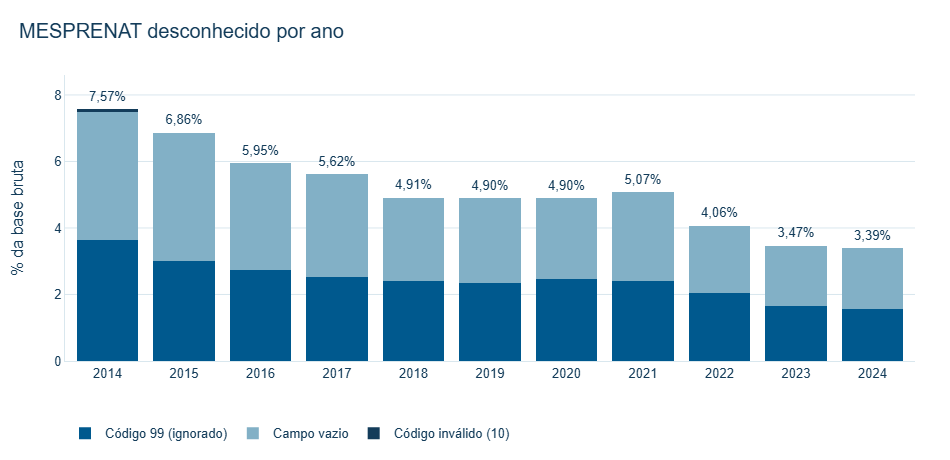

In [6]:
fig = go.Figure()
componentes = [
    ("mesprenat_99_pct", "Código 99 (ignorado)", CORES_IPT["AZUL_PRINCIPAL"]),
    ("mesprenat_vazio_pct", "Campo vazio", CORES_IPT["AZUL_CLARO"]),
    ("mesprenat_outro_pct", "Código inválido (10)", CORES_IPT["AZUL_ESCURO"]),
]
for coluna, nome, cor in componentes:
    fig.add_bar(x=qualidade.index, y=qualidade[coluna], name=nome, marker_color=cor)
fig.add_scatter(
    x=qualidade.index, y=qualidade.t_desconhecido_pct + 0.35, mode="text",
    text=[num(v, 2) + "%" for v in qualidade.t_desconhecido_pct], showlegend=False,
)
fig.update_layout(barmode="stack", legend_traceorder="normal")
fig.update_xaxes(dtick=1)
fig.update_yaxes(title="% da base bruta", range=[0, 8.6])
mostrar(fig, "MESPRENAT desconhecido por ano")

O mês de início é desconhecido quando o campo traz o código 99 ou está vazio. Só em 2014 aparecem também 2.607 registros com o código 10, que não existe no manual de preenchimento. A proporção desconhecida cai de **7,57% (2014)** para **3,39% (2024)**.

Esses registros não significam "sem pré-natal": o mês apenas não foi informado. Eles ficam fora da análise. Como a fração excluída diminui com o tempo, a base analítica de 2014 é um pouco mais seletiva que a de 2024.

### 5.3 Ausências nas características maternas

Percentual de valores ausentes ou ignorados na **base analítica**: registros com mês de início conhecido, peso entre 500 e 6.000 g e gestação única (regras detalhadas no notebook 02).

In [7]:
NOMES_X = {
    "IDADEMAE": "X1 Idade (IDADEMAE)",
    "ESCMAE2010": "X2 Escolaridade (ESCMAE2010)",
    "RACACORMAE": "X3 Raça/cor (RACACORMAE)",
    "ESTCIVMAE": "X4 Situação conjugal (ESTCIVMAE)",
    "PARIDADE": "X5 Paridade (PARIDADE)",
    "QTDFILMORT": "X6 Perdas fetais (QTDFILMORT)",
    "CODMUNRES": "X7 UF de residência (CODMUNRES)",
}
tabela_ausentes = (
    ausentes.pivot(index="variavel", columns="ano", values="pct_total")
    .loc[list(NOMES_X)]
    .rename(index=NOMES_X)
    .rename_axis(index="% ausente ou ignorado", columns="Ano")
)
display(formatar(tabela_ausentes, 2))

Ano,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
% ausente ou ignorado,,,,,,,,,,,
X1 Idade (IDADEMAE),"0,00","0,00","0,00","0,00","0,00","0,00","0,00","0,00","0,00","0,00","0,00"
X2 Escolaridade (ESCMAE2010),"1,37","1,27","1,12","1,12","1,10","0,88","0,83","0,87","0,79","0,55","0,48"
X3 Raça/cor (RACACORMAE),"3,45","3,71","3,81","3,23","2,85","2,41","2,42","2,15","1,85","1,53","1,25"
X4 Situação conjugal (ESTCIVMAE),"0,97","0,92","0,92","0,92","0,88","0,83","0,90","1,05","0,77","0,62","0,61"
X5 Paridade (PARIDADE),"0,00","0,00","0,00","0,00","0,00","0,00","0,00","0,00","0,00","0,00","0,00"
X6 Perdas fetais (QTDFILMORT),"8,37","7,92","7,13","5,85","4,41","3,38","3,31","2,91","2,21","2,08","1,88"
X7 UF de residência (CODMUNRES),"0,00","0,00","0,00","0,00","0,00","0,00","0,00","0,00","0,00","0,00","0,00"


- Perdas fetais (8,37% → 1,88%) e raça/cor (3,45% → 1,25%) concentram as ausências e melhoram muito ao longo do período.
- Idade, paridade e município de residência estão praticamente completos.
- Na análise, ausência numa variável categórica vira a categoria "Ignorado", e o registro não é removido.

Nos indicadores de preenchimento acompanhados aqui, especialmente `MESPRENAT`, perdas fetais e raça/cor, observa-se melhora ao longo do período. Essa conclusão vale para esses campos, não para todos os campos do SINASC. Comparações entre anos misturam mudança real e melhora de registro, sobretudo em 2014–2017.

## 6. Desfecho Y: baixo peso ao nascer

| Valor | Definição |
| --- | --- |
| **Y = 1** | `PESO` < 2.500 g (baixo peso ao nascer, definição da OMS) |
| **Y = 0** | `PESO` ≥ 2.500 g |
| Faixa válida | 500 g ≤ `PESO` ≤ 6.000 g (regra de qualidade do projeto) |

A partir daqui, as estatísticas usam a **base analítica** definida na seção 5.3.

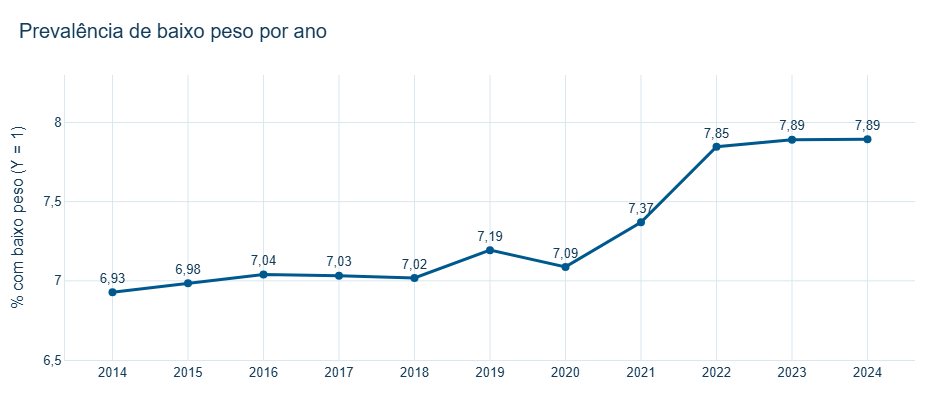

In [8]:
prevalencia = descritiva.prevalencia_y_pct
fig = go.Figure(go.Scatter(
    x=prevalencia.index, y=prevalencia, mode="lines+markers+text",
    text=[num(v, 2) for v in prevalencia], textposition="top center",
    line=dict(color=CORES_IPT["AZUL_PRINCIPAL"], width=3), marker=dict(size=8),
))
fig.update_xaxes(dtick=1)
fig.update_yaxes(title="% com baixo peso (Y = 1)", range=[6.5, 8.3])
mostrar(fig, "Prevalência de baixo peso por ano", altura=420)

A prevalência fica entre 6,9% e 7,2% de 2014 a 2020, sobe para 7,37% em 2021 e se mantém perto de 7,9% de 2022 a 2024. O eixo vertical não começa em zero: a mudança é de cerca de 1 ponto percentual. Este notebook não investiga a causa dessa mudança de nível.

**Distribuição do peso em 2024.** O histograma usa **todos** os registros da base analítica de 2024. A contagem por faixas de 50 g é feita no DuckDB, sem amostragem.

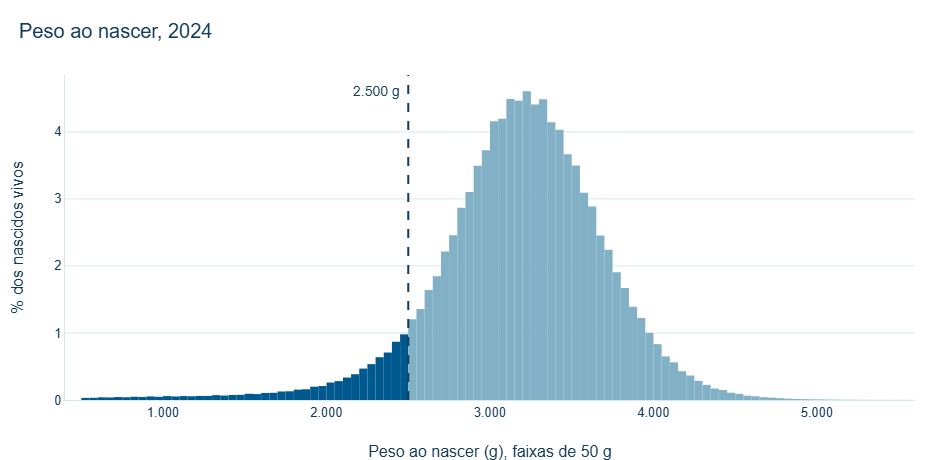

N = 2.251.570 | abaixo de 2.500 g: 7,89% | mediana: 3.190 g | média: 3.150 g


In [9]:
FILTRO_BASE = """
    try_cast(MESPRENAT AS INTEGER) BETWEEN 1 AND 9
    AND try_cast(PESO AS INTEGER) BETWEEN 500 AND 6000
    AND try_cast(GRAVIDEZ AS INTEGER) = 1
"""

peso = con.execute(f"""
    SELECT floor(try_cast(PESO AS INTEGER) / 50) * 50 AS faixa_g, count(*) AS n
    FROM read_parquet('{parquet(2024)}')
    WHERE {FILTRO_BASE}
    GROUP BY 1 ORDER BY 1
""").df()

n_peso = int(peso.n.sum())
pct_baixo = 100 * peso.loc[peso.faixa_g < 2500, "n"].sum() / n_peso
assert n_peso == descritiva.loc[2024, "n_principal"]
assert abs(pct_baixo - descritiva.loc[2024, "prevalencia_y_pct"]) < 1e-4

peso["pct"] = 100 * peso.n / n_peso
cores = np.where(peso.faixa_g < 2500, CORES_IPT["AZUL_PRINCIPAL"], CORES_IPT["AZUL_CLARO"])
fig = go.Figure(go.Bar(x=peso.faixa_g + 25, y=peso.pct, width=50, marker_color=cores, marker_line_width=0))
fig.add_vline(x=2500, line_dash="dash", line_color=CORES_IPT["AZUL_ESCURO"], line_width=2)
fig.add_annotation(x=2500, y=peso.pct.max(), text="2.500 g", showarrow=False,
                   xanchor="right", xshift=-6, font=dict(size=14, color=CORES_IPT["AZUL_ESCURO"]))
fig.update_xaxes(title="Peso ao nascer (g), faixas de 50 g", range=[400, 5600], tickformat=",d")
fig.update_yaxes(title="% dos nascidos vivos")
mostrar(fig, "Peso ao nascer, 2024")

print(f"N = {num(n_peso)} | abaixo de 2.500 g: {num(pct_baixo, 2)}% | "
      f"mediana: {num(descritiva.loc[2024, 'peso_p50_g'])} g | média: {num(descritiva.loc[2024, 'peso_medio_g'])} g")

A distribuição é aproximadamente simétrica em torno de 3.200 g. O baixo peso (barras escuras) corresponde à cauda esquerda e reúne 7,89% dos nascimentos de 2024.

## 7. Idade materna

Distribuição completa da idade da mãe (10 a 59 anos) na base analítica de 2024. A linha mostra 2014 para comparação. Também aqui a contagem usa todos os registros, sem amostragem.

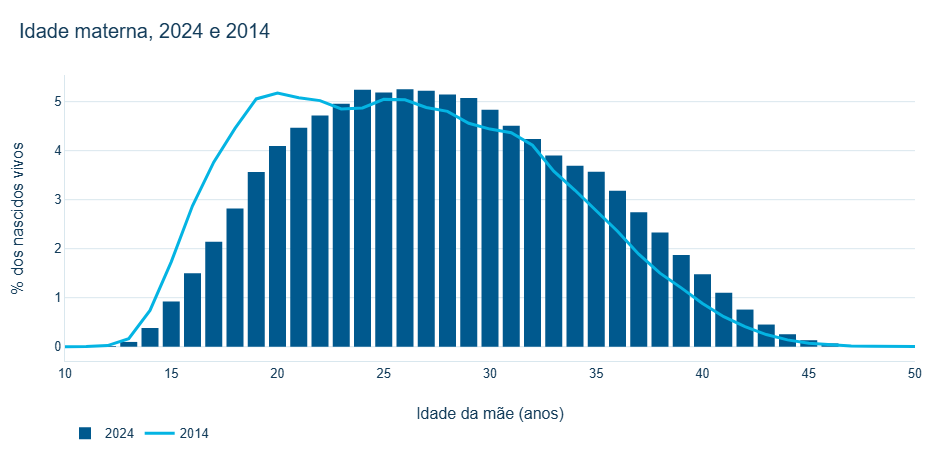

,2014,2024
Idade materna,,
Média (anos),"26,1","27,7"
Mediana (anos),26,27
Menos de 20 anos (%),"18,8","11,4"
35 anos ou mais (%),"12,2","18,0"


In [10]:
def distribuicao_idade(ano):
    return con.execute(f"""
        SELECT try_cast(IDADEMAE AS INTEGER) AS idade, count(*) AS n
        FROM read_parquet('{parquet(ano)}')
        WHERE {FILTRO_BASE} AND try_cast(IDADEMAE AS INTEGER) BETWEEN 10 AND 59
        GROUP BY 1 ORDER BY 1
    """).df().assign(pct=lambda t: 100 * t.n / t.n.sum())


idade = {ano: distribuicao_idade(ano) for ano in (2014, 2024)}

resumo_idade = {}
for ano, t in idade.items():
    media = (t.idade * t.n).sum() / t.n.sum()
    assert abs(media - descritiva.loc[ano, "idade_media"]) < 1e-4
    resumo_idade[ano] = {
        "Média (anos)": num(media, 1),
        "Mediana (anos)": num(t.idade[t.n.cumsum() >= t.n.sum() / 2].iloc[0]),
        "Menos de 20 anos (%)": num(t.loc[t.idade < 20, "pct"].sum(), 1),
        "35 anos ou mais (%)": num(t.loc[t.idade >= 35, "pct"].sum(), 1),
    }

fig = go.Figure()
fig.add_bar(x=idade[2024].idade, y=idade[2024].pct, name="2024", marker_color=CORES_IPT["AZUL_PRINCIPAL"])
fig.add_scatter(x=idade[2014].idade, y=idade[2014].pct, name="2014", mode="lines",
                line=dict(color=CORES_IPT["CIANO"], width=3))
fig.update_xaxes(title="Idade da mãe (anos)", range=[10, 50])
fig.update_yaxes(title="% dos nascidos vivos")
mostrar(fig, "Idade materna, 2024 e 2014")
display(pd.DataFrame(resumo_idade).rename_axis("Idade materna"))

As mães ficaram mais velhas ao longo da década. A idade média passa de 26,1 para 27,7 anos, as mães adolescentes (menos de 20 anos) caem de 18,8% para 11,4%, e as de 35 anos ou mais sobem de 12,2% para 18,0%.

## 8. Exposição T: mês de início do pré-natal

`MESPRENAT` registra o mês de gestação em que ocorreu a primeira consulta de pré-natal. Aqui ele é apenas descrito, entre os registros com mês conhecido (1º a 9º). A definição dos grupos comparados está no notebook 02.

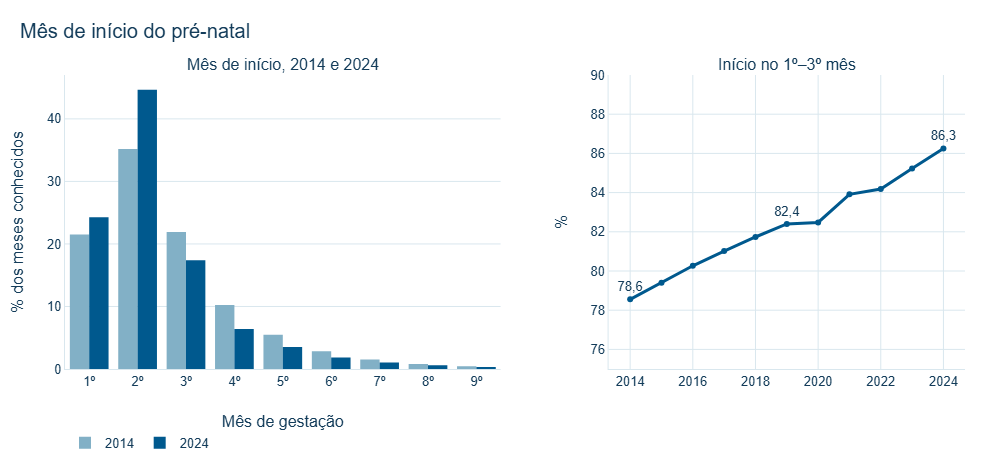

Início no 7º–9º mês: 2014: 2,78%, 2024: 1,95%


In [11]:
meses = list(range(1, 10))
fig = make_subplots(rows=1, cols=2, column_widths=[0.55, 0.45], horizontal_spacing=0.12,
                    subplot_titles=["Mês de início, 2014 e 2024", "Início no 1º–3º mês"])
for ano, cor in ((2014, CORES_IPT["AZUL_CLARO"]), (2024, CORES_IPT["AZUL_PRINCIPAL"])):
    fig.add_bar(x=[f"{m}º" for m in meses], y=[descritiva.loc[ano, f"mes_{m}_pct"] for m in meses],
                name=str(ano), marker_color=cor, row=1, col=1)
precoce = descritiva.prevalencia_t_pct
fig.add_scatter(x=precoce.index, y=precoce, mode="lines+markers+text", showlegend=False,
                text=[num(v, 1) if a in (2014, 2019, 2024) else "" for a, v in precoce.items()],
                textposition="top center", line=dict(color=CORES_IPT["AZUL_PRINCIPAL"], width=3),
                row=1, col=2)
fig.update_xaxes(title="Mês de gestação", row=1, col=1)
fig.update_xaxes(dtick=2, row=1, col=2)
fig.update_yaxes(title="% dos meses conhecidos", row=1, col=1)
fig.update_yaxes(title="%", range=[75, 90], row=1, col=2)
mostrar(fig, "Mês de início do pré-natal", altura=470, largura=1000)

tardio = {ano: sum(descritiva.loc[ano, f"mes_{m}_pct"] for m in (7, 8, 9)) for ano in (2014, 2024)}
print("Início no 7º–9º mês:", ", ".join(f"{a}: {num(v, 2)}%" for a, v in tardio.items()))

- O **2º mês** é o mais comum, e sua participação cresce de 35,2% para 44,7%.
- A proporção de início no 1º–3º mês sobe de forma quase linear: de **78,55% (2014)** para **86,25% (2024)**.
- Inícios no 7º–9º mês são raros (menos de 3%) e ficam cada vez mais raros.

Com o tempo, o grupo que começa tarde fica menor e, possivelmente, mais selecionado.

## 9. Características maternas X

As sete dimensões usadas para comparar gestantes semelhantes são idade, escolaridade, raça/cor, situação conjugal, paridade, perdas fetais anteriores e UF de residência. A tabela resume a composição da base analítica em 2014 e 2024. Para a UF, a composição é agregada por região.

In [12]:
linhas = [("X1 Idade", "Média (anos)", descritiva.loc[2014, "idade_media"], descritiva.loc[2024, "idade_media"])]
for variavel, dimensao in DIMENSOES.items():
    sub = covariaveis[covariaveis.variavel == variavel].pivot(index="categoria", columns="ano", values="pct")
    for categoria, rotulo in ROTULOS[variavel].items():
        if categoria in sub.index:
            linhas.append((dimensao, rotulo, sub.loc[categoria, 2014], sub.loc[categoria, 2024]))

regioes = (geografia.assign(regiao=geografia.uf.str[0].map(REGIAO))
           .groupby(["ano", "regiao"]).n_principal.sum().unstack("ano"))
regioes = 100 * regioes / regioes.sum()
for regiao in REGIAO.values():
    linhas.append(("X7 UF (por região)", regiao, regioes.loc[regiao, 2014], regioes.loc[regiao, 2024]))

composicao = pd.DataFrame(linhas, columns=["Dimensão", "Categoria", "2014", "2024"]).set_index(["Dimensão", "Categoria"])
composicao["Variação (p.p.)"] = composicao["2024"] - composicao["2014"]
composicao.loc[("X1 Idade", "Média (anos)"), "Variação (p.p.)"] = np.nan
display(formatar(composicao, 1))

2014  2024 Variação (p.p.)
Dimensão             Categoria                                      
X1 Idade             Média (anos)         26,1  27,7               —
X2 Escolaridade      Sem escolaridade      0,5   0,2            -0,3
                     Fundamental I         5,9   1,9            -3,9
                     Fundamental II       26,3  16,8            -9,5
                     Médio                48,3  55,7             7,4
                     Superior incompleto   4,8   5,2             0,4
                     Superior completo    12,8  19,7             6,8
                     Ignorado              1,4   0,5            -0,9
X3 Raça/cor          Branca               36,8  33,4            -3,4
                     Preta                 5,1   7,9             2,8
                     Amarela               0,4   0,5             0,1
                     Parda                53,5  55,7             2,2
                     Indígena              0,7   1,2             0,5
                     Ignorado              3,4   1,3            -2,2
X4 Situação conjugal Solteira             40,0  51,9            11,9
                     Casada               33,1  31,6            -1,5
                     Viúva                 0,2   0,2            -0,0
                     Separada/divorciada   1,0   1,7             0,7
                     União estável        24,6  14,0           -10,6
                     Ignorado              1,0   0,6            -0,4
X5 Paridade          Nulípara             41,7  36,9            -4,8
                     Multípara            58,3  63,1             4,8
X6 Perdas fetais     Nenhuma              74,8  76,9             2,1
                     Uma                  13,6  16,8             3,1
                     Duas ou mais          3,3   4,5             1,2
                     Ignorado              8,4   1,9            -6,5
X7 UF (por região)   Norte                10,5  10,9             0,4
                     Nordeste             27,3  27,5             0,3
                     Sudeste              40,2  38,0            -2,2
                     Sul                  13,8  14,3             0,6
                     Centro-Oeste          8,3   9,2             0,9

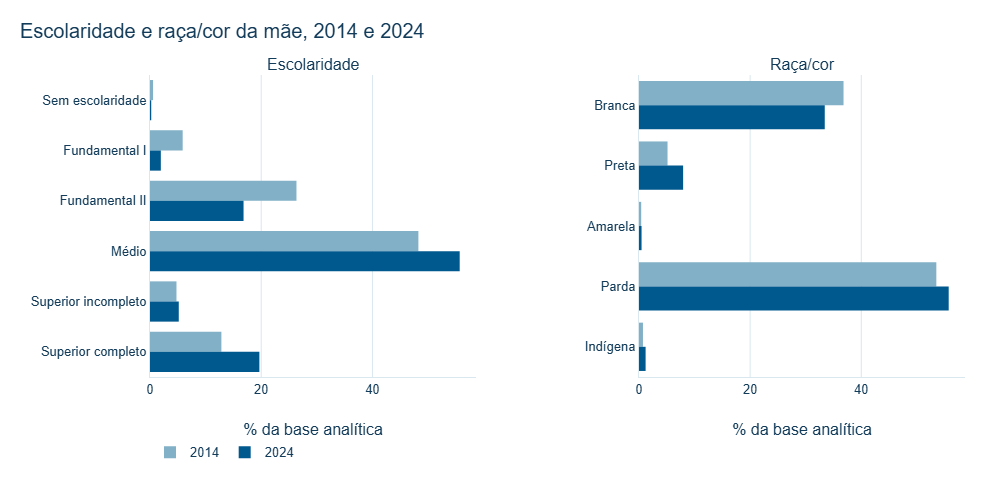

In [13]:
fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.2,
                    subplot_titles=["Escolaridade", "Raça/cor"])
for coluna, variavel in enumerate(("ESCOLARIDADE_MAE", "RACA_COR_MAE"), start=1):
    sub = covariaveis[(covariaveis.variavel == variavel) & (covariaveis.categoria != "IGNORADO")]
    for ano, cor in ((2014, CORES_IPT["AZUL_CLARO"]), (2024, CORES_IPT["AZUL_PRINCIPAL"])):
        s = sub[sub.ano == ano].set_index("categoria").pct
        fig.add_bar(y=[ROTULOS[variavel][k] for k in s.index], x=s.values, orientation="h",
                    name=str(ano), marker_color=cor, showlegend=coluna == 1, row=1, col=coluna)
fig.update_yaxes(autorange="reversed")
fig.update_xaxes(title="% da base analítica")
mostrar(fig, "Escolaridade e raça/cor da mãe, 2014 e 2024", altura=480, largura=1000, margem_esquerda=150)

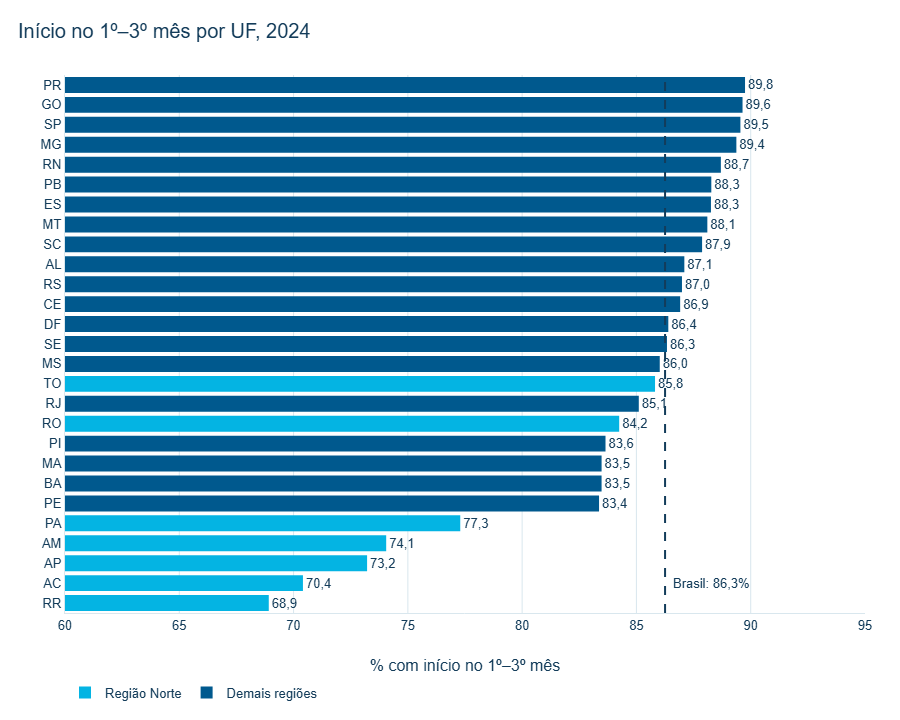

In [14]:
uf24 = (geografia[(geografia.ano == 2024) & geografia.uf.isin(UF_SIGLA)]
        .assign(sigla=lambda t: t.uf.map(UF_SIGLA), regiao=lambda t: t.uf.str[0].map(REGIAO))
        .sort_values("pct_t1"))
grupos_uf = {"Região Norte": uf24.regiao == "Norte", "Demais regiões": uf24.regiao != "Norte"}
cores_uf = {"Região Norte": CORES_IPT["CIANO"], "Demais regiões": CORES_IPT["AZUL_PRINCIPAL"]}
fig = go.Figure()
for nome, mascara in grupos_uf.items():
    sub = uf24[mascara]
    fig.add_bar(y=sub.sigla, x=sub.pct_t1, orientation="h", name=nome, marker_color=cores_uf[nome],
                text=[num(v, 1) for v in sub.pct_t1], textposition="outside")
nacional = descritiva.loc[2024, "prevalencia_t_pct"]
fig.add_vline(x=nacional, line_dash="dash", line_color=CORES_IPT["AZUL_ESCURO"])
fig.add_annotation(x=nacional, y=uf24.sigla.iloc[1], text=f"Brasil: {num(nacional, 1)}%",
                   showarrow=False, xanchor="left", xshift=6)
fig.update_yaxes(categoryorder="array", categoryarray=list(uf24.sigla))
fig.update_xaxes(title="% com início no 1º–3º mês", range=[60, 95])
fig.update_layout(barmode="overlay", legend=dict(y=-0.12))
mostrar(fig, "Início no 1º–3º mês por UF, 2024", altura=720, largura=900)

- **Composição em mudança gradual:** mais mães com ensino superior completo e menos com até o fundamental II, aumento da proporção de mães pretas e solteiras, idade média maior.
- **Geografia:** todas as UFs têm maioria de início no 1º–3º mês, mas os níveis são muito diferentes. Os menores valores estão em cinco estados do Norte (RR, AC, AP, AM e PA, entre 69% e 77%). As demais UFs, incluindo RO e TO, ficam entre 83% e 90%.

Essas mesmas características também variam entre quem começa cedo e quem começa tarde, como mostra a próxima seção.

## 10. Início precoce versus início no 4º–6º mês

Para antecipar o desenho do notebook 02, a tabela compara as gestantes com início no **1º–3º mês (T = 1)** às com início no **4º–6º mês (T = 0)**, que é a comparação principal do projeto. A tabela usa todos os registros de 2024 e, como contraste temporal, de 2014. Os valores são percentuais dentro de cada grupo, salvo indicação.

Não há testes de hipótese: com milhões de registros, qualquer diferença seria "significativa". O objetivo é apenas verificar se as características observadas estão distribuídas de forma semelhante nos dois grupos **antes** de qualquer ajuste.

In [15]:
# Mesmas recodificações usadas na análise (ver DICIONARIO_TECNICO.md)
SQL_GRUPOS = """
SELECT
    CASE WHEN try_cast(MESPRENAT AS INTEGER) <= 3 THEN 1 ELSE 0 END AS T,
    CAST(try_cast(PESO AS INTEGER) < 2500 AS INTEGER) AS Y,
    CASE WHEN try_cast(IDADEMAE AS INTEGER) BETWEEN 10 AND 59
         THEN try_cast(IDADEMAE AS DOUBLE) END AS IDADE,
    CASE WHEN try_cast(ESCMAE2010 AS INTEGER) = 9 OR ESCMAE2010 IS NULL
         THEN 'IGNORADO' ELSE CAST(try_cast(ESCMAE2010 AS INTEGER) AS VARCHAR) END AS ESCOLARIDADE_MAE,
    CASE WHEN try_cast(RACACORMAE AS INTEGER) = 9 OR RACACORMAE IS NULL
         THEN 'IGNORADO' ELSE CAST(try_cast(RACACORMAE AS INTEGER) AS VARCHAR) END AS RACA_COR_MAE,
    CASE WHEN try_cast(ESTCIVMAE AS INTEGER) = 9 OR ESTCIVMAE IS NULL
         THEN 'IGNORADO' ELSE CAST(try_cast(ESTCIVMAE AS INTEGER) AS VARCHAR) END AS SITUACAO_CONJUGAL,
    CASE WHEN try_cast(PARIDADE AS INTEGER) IN (9, 99) OR PARIDADE IS NULL
         THEN 'IGNORADO' ELSE CAST(try_cast(PARIDADE AS INTEGER) AS VARCHAR) END AS PARIDADE_CAT,
    CASE WHEN try_cast(QTDFILMORT AS INTEGER) = 0 THEN '0'
         WHEN try_cast(QTDFILMORT AS INTEGER) = 1 THEN '1'
         WHEN try_cast(QTDFILMORT AS INTEGER) BETWEEN 2 AND 98 THEN '2_OU_MAIS'
         ELSE 'IGNORADO' END AS PERDAS_FETAIS_CAT
FROM read_parquet('{caminho}')
WHERE try_cast(MESPRENAT AS INTEGER) BETWEEN 1 AND 6
  AND try_cast(PESO AS INTEGER) BETWEEN 500 AND 6000
  AND try_cast(GRAVIDEZ AS INTEGER) = 1
"""


def resumo_por_grupo(ano):
    con.execute(f"CREATE OR REPLACE TEMP TABLE grupos AS {SQL_GRUPOS.format(caminho=parquet(ano))}")
    gerais = con.execute("""
        SELECT T, count(*) AS n, avg(IDADE) AS idade_media, stddev_samp(IDADE) AS idade_dp,
               100 * avg(CAST(IDADE < 20 AS INTEGER)) AS idade_menor_20, 100 * avg(Y) AS y_pct
        FROM grupos GROUP BY T
    """).df().set_index("T")
    categorias = {
        variavel: con.execute(f"SELECT T, {variavel} AS categoria, count(*) AS n FROM grupos GROUP BY ALL")
                     .df().pivot(index="categoria", columns="T", values="n").fillna(0)
        for variavel in DIMENSOES
    }
    return gerais, categorias


grupos = {ano: resumo_por_grupo(ano) for ano in (2024, 2014)}

# Conferência: o grupo T = 1 é idêntico ao das tabelas consolidadas do projeto
assert grupos[2024][0].n.to_dict() == {1: 1_942_045, 0: 265_169}
for ano, (gerais, categorias) in grupos.items():
    assert abs(gerais.loc[1, "y_pct"] - descritiva.loc[ano, "risco_y_t1_pct"]) < 1e-4
    for variavel, tabela in categorias.items():
        esperado = covariaveis[(covariaveis.ano == ano) & (covariaveis.variavel == variavel)].set_index("categoria").n_t1
        assert tabela[1].astype(int).sort_index().equals(esperado.astype(int).sort_index()), (ano, variavel)
print("Contagens de T = 1 conferem com as tabelas consolidadas (2014 e 2024).")

Contagens de T = 1 conferem com as tabelas consolidadas (2014 e 2024).


In [16]:
def coluna_tabela1(ano, t):
    gerais, categorias = grupos[ano]
    g = gerais.loc[t]
    valores = {
        ("Total", "N"): g.n,
        ("X1 Idade", "Média (anos)"): g.idade_media,
        ("X1 Idade", "Desvio-padrão (anos)"): g.idade_dp,
        ("X1 Idade", "Menos de 20 anos"): g.idade_menor_20,
    }
    for variavel, dimensao in DIMENSOES.items():
        tabela = categorias[variavel]
        for categoria, rotulo in ROTULOS[variavel].items():
            if categoria in tabela.index:
                valores[(dimensao, rotulo)] = 100 * tabela.loc[categoria, t] / tabela[t].sum()
    valores[("Desfecho", "Baixo peso (Y = 1)")] = g.y_pct
    return pd.Series(valores)


tabela1 = pd.DataFrame({
    ("2024", "T = 1 (1º–3º mês)"): coluna_tabela1(2024, 1),
    ("2024", "T = 0 (4º–6º mês)"): coluna_tabela1(2024, 0),
    ("2014", "T = 1 (1º–3º mês)"): coluna_tabela1(2014, 1),
    ("2014", "T = 0 (4º–6º mês)"): coluna_tabela1(2014, 0),
})
tabela1.insert(2, ("2024", "Diferença (p.p.)"), tabela1.iloc[:, 0] - tabela1.iloc[:, 1])
tabela1.loc[("Total", "N"), ("2024", "Diferença (p.p.)")] = np.nan
tabela1.loc[[("X1 Idade", "Média (anos)"), ("X1 Idade", "Desvio-padrão (anos)")], ("2024", "Diferença (p.p.)")] = np.nan

exibicao = tabela1.map(lambda v: "—" if pd.isna(v) else num(v, 1))
exibicao.loc[("Total", "N")] = [num(v) if pd.notna(v) else "—" for v in tabela1.loc[("Total", "N")]]
exibicao.index.names = ["Dimensão", "Característica"]
display(exibicao)

2024                                                 2014                  
                                          T = 1 (1º–3º mês) T = 0 (4º–6º mês) Diferença (p.p.) T = 1 (1º–3º mês) T = 0 (4º–6º mês)
Dimensão             Característica                                                                                               
Total                N                            1.942.045           265.169                —         2.113.992           501.781
X1 Idade             Média (anos)                      28,0              26,4                —              26,6              24,5
                     Desvio-padrão (anos)               6,6               7,0                —               6,5               6,7
                     Menos de 20 anos                  10,4              18,0             -7,6              16,5              27,5
X2 Escolaridade      Sem escolaridade                   0,2               0,5             -0,4               0,4               1,0
                     Fundamental I                      1,7               3,4             -1,7               4,9               9,1
                     Fundamental II                    15,3              26,0            -10,7              23,5              36,8
                     Médio                             55,7              55,9             -0,1              49,5              44,4
                     Superior incompleto                5,3               4,2              1,1               5,2               3,1
                     Superior completo                 21,3               9,5             11,8              15,2               4,1
                     Ignorado                           0,5               0,6             -0,1               1,3               1,5
X3 Raça/cor          Branca                            34,9              24,5             10,4              40,0              25,3
                     Preta                              7,7               9,6             -1,9               4,8               6,4
                     Amarela                            0,5               0,4              0,1               0,4               0,3
                     Parda                             54,8              61,6             -6,8              50,9              63,2
                     Indígena                           0,9               2,7             -1,8               0,5               1,4
                     Ignorado                           1,2               1,2             -0,0               3,5               3,3
X4 Situação conjugal Solteira                          49,9              64,6            -14,7              37,2              50,5
                     Casada                            33,8              17,8             16,0              37,3              17,9
                     Viúva                              0,2               0,2             -0,0               0,2               0,2
                     Separada/divorciada                1,8               1,3              0,4               1,1               0,8
                     União estável                     13,8              15,3             -1,6              23,3              29,6
                     Ignorado                           0,6               0,7             -0,1               0,9               1,1
X5 Paridade          Nulípara                          37,9              31,0              6,9              43,4              36,3
                     Multípara                         62,1              69,0             -6,9              56,6              63,7
X6 Perdas fetais     Nenhuma                           76,7              77,8             -1,1              74,8              74,4
                     Uma                               16,9              15,8              1,1              13,8              12,9
                     Duas ou mais                       4,5               4,3              0,2               3,2             

Os grupos apresentam **desequilíbrios relevantes nas características observadas** antes do ajuste. Em 2024, em relação a quem inicia no 4º–6º mês, quem inicia no 1º–3º mês:

- é, em média, 1,6 ano mais velha, e a proporção de adolescentes é bem menor;
- tem ensino superior completo com frequência bem maior;
- é casada com mais frequência e solteira com menos frequência;
- é branca com mais frequência, e parda ou indígena com menos frequência;
- é nulípara (primeira gestação) com mais frequência.

O padrão de 2014 é o mesmo. O baixo peso é menor no grupo T = 1, mas **essa diferença bruta não é um efeito do pré-natal**: ela mistura o possível papel do momento de início com as diferenças de perfil acima. Separar as duas coisas é o objetivo dos notebooks seguintes.

## 11. Evolução temporal resumida

Indicadores centrais da base de 2014 a 2024. O baixo peso e o início no 1º–3º mês são calculados na base analítica. O `MESPRENAT` desconhecido é calculado na base bruta.

In [17]:
evolucao = pd.DataFrame({
    "N bruto": descritiva.n_bruto.map(num),
    "Baixo peso, Y = 1 (%)": descritiva.prevalencia_y_pct.map(lambda v: num(v, 2)),
    "Início no 1º–3º mês (%)": descritiva.prevalencia_t_pct.map(lambda v: num(v, 2)),
    "MESPRENAT desconhecido (%)": qualidade.t_desconhecido_pct.map(lambda v: num(v, 2)),
}).rename_axis("Ano")
display(evolucao)

,N bruto,"Baixo peso, Y = 1 (%)",Início no 1º–3º mês (%),MESPRENAT desconhecido (%)
Ano,,,,
2014,2.979.259,"6,93","78,55","7,57"
2015,3.017.668,"6,98","79,40","6,86"
2016,2.857.800,"7,04","80,27","5,95"
2017,2.923.535,"7,03","81,02","5,62"
2018,2.944.932,"7,02","81,74","4,91"
2019,2.849.146,"7,19","82,40","4,90"
2020,2.730.145,"7,09","82,48","4,90"
2021,2.677.101,"7,37","83,91","5,07"
2022,2.561.922,"7,85","84,18","4,06"


## 12. Síntese da análise exploratória

1. **Grande volume, estrutura estável.** São 30,5 milhões de registros em onze anos, com 61 a 62 colunas e uma chave única por ano. Uma linha corresponde a um nascido vivo.
2. **Menos nascimentos.** O número de nascidos vivos cai cerca de 20% entre 2014 e 2024.
3. **Mais início precoce.** A proporção de início do pré-natal no 1º–3º mês sobe de 78,6% para 86,3%. O grupo que começa tarde fica menor a cada ano.
4. **Baixo peso estável e depois mais alto.** A prevalência fica entre 6,9% e 7,2% até 2020 e perto de 7,9% em 2022–2024.
5. **Preenchimento melhor nos campos acompanhados.** O mês de início desconhecido cai de 7,6% para 3,4%, e as ausências em perdas fetais e raça/cor também diminuem.
6. **Desequilíbrios entre os grupos.** Quem começa o pré-natal cedo difere nas características observadas (mais velha, mais escolarizada, mais frequentemente casada). Uma comparação direta de baixo peso entre os grupos não isola o papel do pré-natal.

Esses achados são **descritivos**. O notebook 02 define a população analítica, a exposição, o desfecho e as covariáveis que permitem fazer a comparação de forma ajustada.